In [68]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

In [69]:
seed = 42

def random_number():
    global seed
    seed = (16807 * seed) % 2147483647
    return seed / 2147483647

def random_array(n):
    return np.array([random_number() for _ in range(n)])

def random_index(n):
    return int(random_number() * n)

def shuffle_indices(n):
    indices = list(range(n))

    for i in range(n - 1, 0, -1):
        j = random_index(i + 1)
        indices[i], indices[j] = indices[j], indices[i]

    return np.array(indices)

In [70]:
def box_muller(n):
    u1 = np.maximum(random_array(n), 1e-10)
    u2 = random_array(n)

    z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
    z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

    return np.column_stack((z1, z2))

In [71]:
def generate_gaussian(n, mean, sigma_x, sigma_y,
                      covariance_type="spherical", rho=0):

    z = box_muller(n)

    if covariance_type == "spherical":
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_y * z[:, 1]

    else:
        x = mean[0] + sigma_x * z[:, 0]
        y = mean[1] + sigma_y * (
            rho * z[:, 0] + np.sqrt(1 - rho**2) * z[:, 1]
        )

    return np.column_stack((x, y))

In [72]:
n_samples = 1500
K = 3

pi1 = [1/3, 1/3, 1/3]
pi2 = [1/3, 1/3, 1/3]

means_class1 = [
    [3, 2],
    [3, 5],
    [3, 8]
]

means_class2 = [
    [9, 2],
    [9, 5],
    [9, 8]
]

sigma_x = 1.2
sigma_y = 0.8
rho = 0.6

In [73]:
def generate_gmm(n, means, weights, covariance_type,
                 sigma_x, sigma_y, rho):

    component = []

    for i in range(n):
        r = random_number()
        total = 0

        for j in range(len(weights)):
            total += weights[j]

            if r <= total:
                component.append(j)
                break

    component = np.array(component)
    X = np.zeros((n, 2))

    for i in range(len(means)):
        count = np.sum(component == i)

        if count > 0:
            X[component == i] = generate_gaussian(
                count, means[i], sigma_x, sigma_y,
                covariance_type, rho
            )

    return X, component

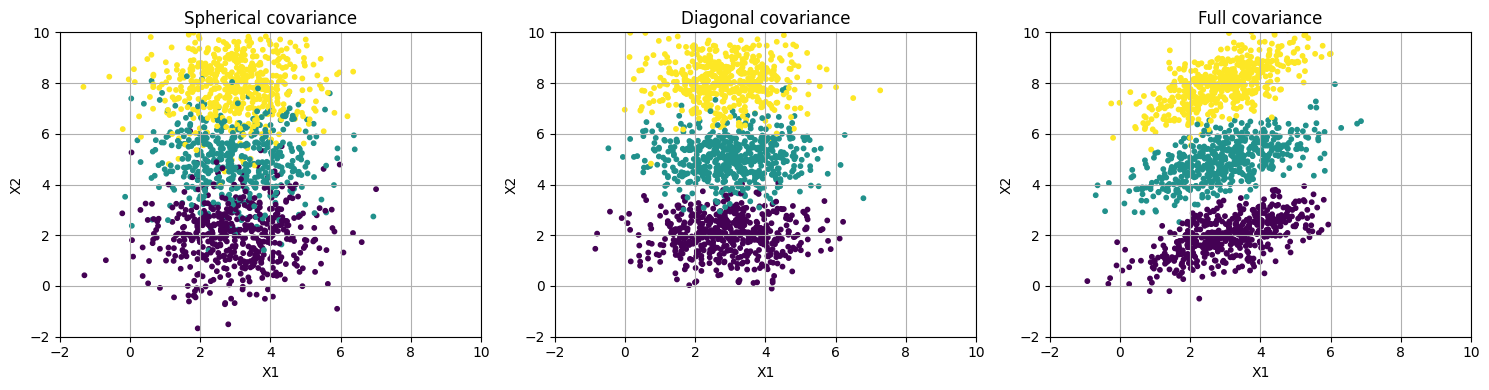

In [177]:
covariance_types = ["spherical", "diagonal", "full"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    X, components = generate_gmm(
        1500, means_class1, pi1, cov_type,
        sigma_x, sigma_y, rho
    )

    ax.scatter(X[:, 0], X[:, 1], c=components, s=10)
    ax.set_title(cov_type.capitalize() + " covariance")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-2, 10)
    ax.set_ylim(-2, 10)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [75]:
X1, component1 = generate_gmm(
    n_samples, means_class1, pi1, "full",
    sigma_x, sigma_y, rho
)

X2, component2 = generate_gmm(
    n_samples, means_class2, pi2, "full",
    sigma_x, sigma_y, rho
)

print("Class 1 data:", X1.shape)
print("Class 2 data:", X2.shape)

Class 1 data: (1500, 2)
Class 2 data: (1500, 2)


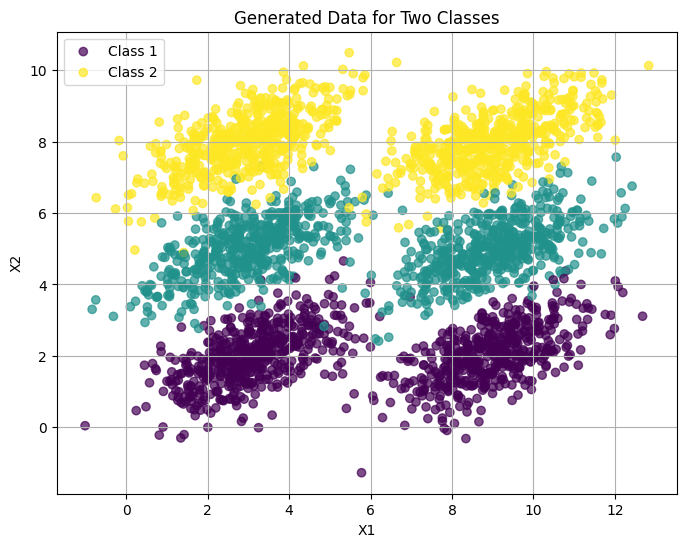

In [76]:
plt.figure(figsize=(8, 6))

plt.scatter(X1[:, 0], X1[:, 1], c=component1, label="Class 1", alpha=0.7)
plt.scatter(X2[:, 0], X2[:, 1], c=component2, label="Class 2", alpha=0.7)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Generated Data for Two Classes")
plt.legend()
plt.grid(True)
plt.show()

In [77]:
def train_test_split(X):
    indices = shuffle_indices(len(X))
    split = int(0.8 * len(X))

    train = X[indices[:split]]
    test = X[indices[split:]]

    return train, test

X1_train, X1_test = train_test_split(X1)
X2_train, X2_test = train_test_split(X2)

print("Class 1 training:", len(X1_train))
print("Class 1 testing:", len(X1_test))
print("Class 2 training:", len(X2_train))
print("Class 2 testing:", len(X2_test))

Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300


In [78]:
def kmeans(X, K, max_iterations=100):
    indices = shuffle_indices(len(X))
    centroids = X[indices[:K]].copy()

    for _ in range(max_iterations):
        distances = np.zeros((len(X), K))

        for j in range(K):
            distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(K):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        if np.sum((new_centroids - centroids)**2) < 1e-8:
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.zeros((len(X), K))

    for j in range(K):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    labels = np.argmin(distances, axis=1)

    return centroids, labels

In [79]:
centroids1, labels1 = kmeans(X1_train, K)
centroids2, labels2 = kmeans(X2_train, K)

print("Class 1 centroids:")
print(centroids1)

print("\nClass 2 centroids:")
print(centroids2)

Class 1 centroids:
[[2.99305365 1.99492104]
 [2.98455627 5.09667975]
 [3.05704681 8.09469251]]

Class 2 centroids:
[[8.73455436 1.92465213]
 [9.14531221 7.9490342 ]
 [8.99320369 4.89766787]]


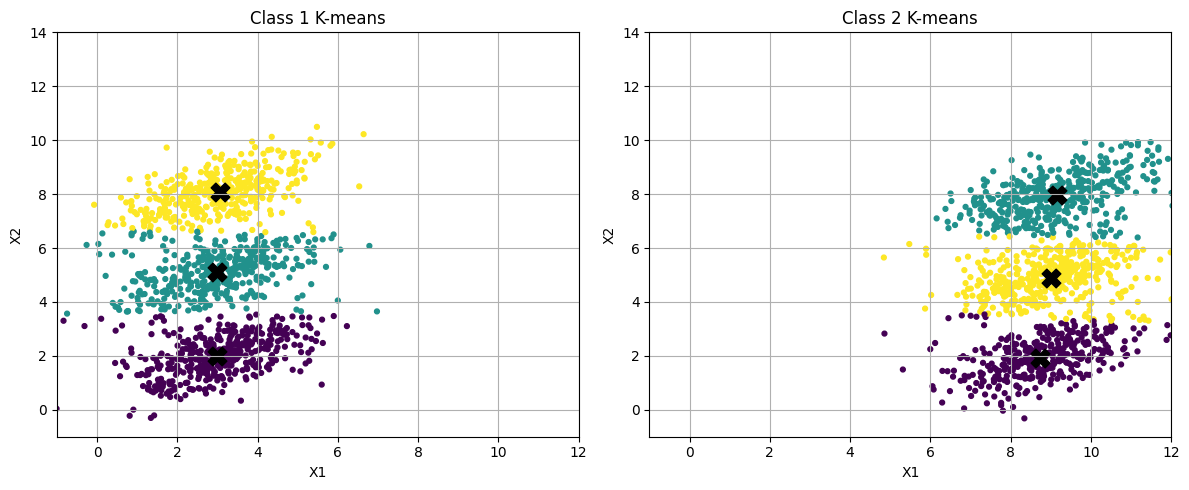

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X1_train[:, 0], X1_train[:, 1], c=labels1, s=12)
axes[0].scatter(centroids1[:, 0], centroids1[:, 1],
                marker="X", s=180, c="black")
axes[0].set_title("Class 1 K-means")

axes[1].scatter(X2_train[:, 0], X2_train[:, 1], c=labels2, s=12)
axes[1].scatter(centroids2[:, 0], centroids2[:, 1],
                marker="X", s=180, c="black")
axes[1].set_title("Class 2 K-means")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_xlim(-1, 12)
    ax.set_ylim(-1, 14)
    ax.grid(True)

plt.tight_layout()
plt.show()

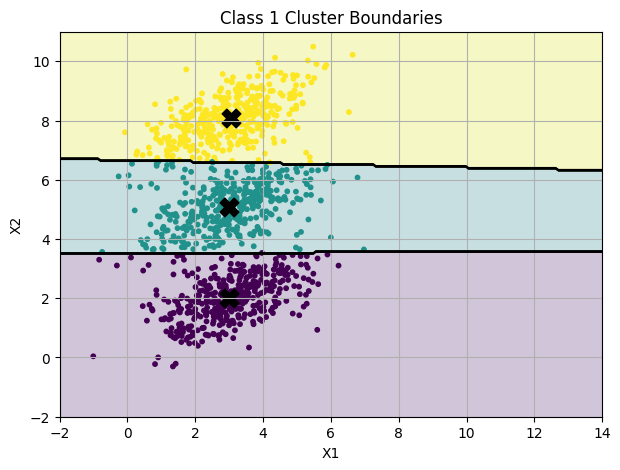

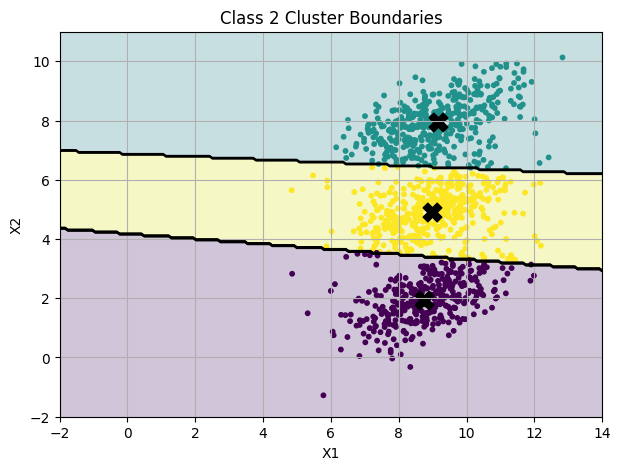

In [81]:

def plot_boundaries(X, centroids, labels, title):
    x_min, x_max = -2, 14
    y_min, y_max = -2, 11

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))
    distances = np.zeros((len(grid), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((grid - centroids[j])**2, axis=1)

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, regions, alpha=0.25)
    plt.contour(xx, yy, regions, colors="black", linewidths=1)

    plt.scatter(X[:, 0], X[:, 1], c=labels, s=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker="X", s=180, c="black")

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.grid(True)
    plt.show()

plot_boundaries(X1_train, centroids1, labels1, "Class 1 Cluster Boundaries")
plot_boundaries(X2_train, centroids2, labels2, "Class 2 Cluster Boundaries")


In [82]:
def calculate_distortion(X, centroids):
    distances = np.zeros((len(X), len(centroids)))

    for j in range(len(centroids)):
        distances[:, j] = np.sum((X - centroids[j])**2, axis=1)

    return np.min(distances, axis=1)

def classify(X):
    distortion1 = calculate_distortion(X, centroids1)
    distortion2 = calculate_distortion(X, centroids2)

    predictions = np.where(distortion1 < distortion2, 0, 1)

    return predictions

In [83]:
X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

predictions = classify(X_test)

accuracy = np.mean(predictions == y_test) * 100

print("Total test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification accuracy:", round(accuracy, 2), "%")

Total test samples: 600
Correct predictions: 595
Incorrect predictions: 5
Classification accuracy: 99.17 %


In [84]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[298   2]
 [  3 297]]


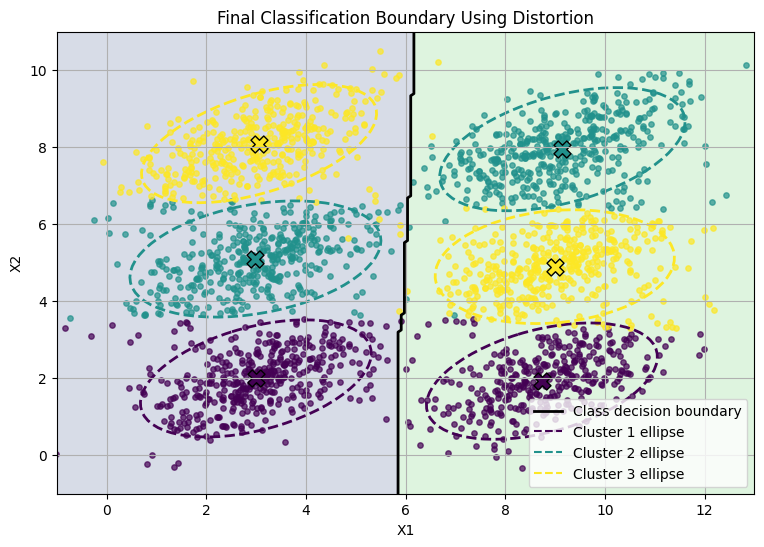

In [85]:

from matplotlib.patches import Ellipse

all_train = np.vstack((X1_train, X2_train))

x_min = all_train[:, 0].min() - 1
x_max = all_train[:, 0].max() + 1
y_min = all_train[:, 1].min() - 1
y_max = all_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))
regions = classify(grid).reshape(xx.shape)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.2
)

plt.contour(
    xx, yy, regions,
    levels=[0.5],
    colors="black",
    linewidths=2
)

colors = ["#440154", "#21918c", "#fde725"]

for i in range(3):
    plt.scatter(
        X1_train[labels1 == i, 0],
        X1_train[labels1 == i, 1],
        color=colors[i], s=15, alpha=0.7
    )

    plt.scatter(
        X2_train[labels2 == i, 0],
        X2_train[labels2 == i, 1],
        color=colors[i], s=15, alpha=0.7
    )

for X, labels, centroids in [
    (X1_train, labels1, centroids1),
    (X2_train, labels2, centroids2)
]:
    for i in range(3):
        points = X[labels == i]

        center_x = centroids[i, 0]
        center_y = centroids[i, 1]

        cov = np.zeros((2, 2))

        if len(points) > 1:
            centered = points - np.mean(points, axis=0)
            cov = centered.T @ centered / (len(points) - 1)

        values, vectors = np.linalg.eigh(cov)
        order = np.argsort(values)[::-1]
        values = values[order]
        vectors = vectors[:, order]

        angle = np.degrees(np.arctan2(
            vectors[1, 0], vectors[0, 0]
        ))

        width = 4 * np.sqrt(max(values[0], 0))
        height = 4 * np.sqrt(max(values[1], 0))

        plt.gca().add_patch(
            Ellipse(
                (center_x, center_y),
                width=width,
                height=height,
                angle=angle,
                fill=False,
                edgecolor=colors[i],
                linestyle="--",
                linewidth=2
            )
        )

        plt.scatter(
            center_x, center_y,
            marker="X", s=150,
            color=colors[i], edgecolors="black"
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Final Classification Boundary Using Distortion")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend(
    handles=[
        plt.Line2D([0], [0], color="black", linewidth=2,
                   label="Class decision boundary"),
        plt.Line2D([0], [0], color=colors[0], linestyle="--",
                   label="Cluster 1 ellipse"),
        plt.Line2D([0], [0], color=colors[1], linestyle="--",
                   label="Cluster 2 ellipse"),
        plt.Line2D([0], [0], color=colors[2], linestyle="--",
                   label="Cluster 3 ellipse")
    ],
    loc="lower right"
)
plt.xlim(-1, 13)
plt.ylim(-1, 11)
plt.grid(True)
plt.show()


In [122]:
X_train = np.vstack((X1_train, X2_train))

y_train = np.concatenate((
    np.zeros(len(X1_train), dtype=int),
    np.ones(len(X2_train), dtype=int)
))

X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (2400, 2)
Testing data shape: (600, 2)
Training labels shape: (2400,)
Testing labels shape: (600,)


In [123]:
import numpy as np

def gaussian_pdf(X, mean, covariance):
    """Calculate multivariate Gaussian probability density."""
    d = X.shape[1]
    covariance = covariance + 1e-6 * np.eye(d)

    sign, log_det = np.linalg.slogdet(covariance)
    if sign <= 0:
        covariance = covariance + 1e-4 * np.eye(d)
        sign, log_det = np.linalg.slogdet(covariance)

    diff = X - mean
    solved = np.linalg.solve(covariance, diff.T).T
    mahalanobis = np.sum(diff * solved, axis=1)

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi) + log_det + mahalanobis
    )
    return np.exp(np.maximum(log_pdf, -700))


def train_gmm(X, K, max_iter=100, tol=1e-4, seed=42):
    """Train a full-covariance GMM using the EM algorithm."""
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_cov = np.cov(X, rowvar=False)
    global_cov = np.atleast_2d(global_cov) + 1e-5 * np.eye(d)

    covariances = np.array([global_cov.copy() for _ in range(K)])
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        probabilities = np.column_stack([
            weights[k] * gaussian_pdf(X, means[k], covariances[k])
            for k in range(K)
        ])

        row_sums = np.maximum(probabilities.sum(axis=1), 1e-300)
        responsibilities = probabilities / row_sums[:, None]
        log_likelihood = np.sum(np.log(row_sums))

        Nk = responsibilities.sum(axis=0)
        Nk = np.maximum(Nk, 1e-8)

        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            covariances[k] = (
                (diff * responsibilities[:, k, None]).T @ diff
            ) / Nk[k]
            covariances[k] += 1e-5 * np.eye(d)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "covariances": covariances
    }


class1_train = X_train[y_train == 0]
class2_train = X_train[y_train == 1]

gmm1 = train_gmm(class1_train, K, seed=42)
gmm2 = train_gmm(class2_train, K, seed=43)

print("GMM for Class 1 trained successfully")
print("GMM for Class 2 trained successfully")

GMM for Class 1 trained successfully
GMM for Class 2 trained successfully


In [124]:

def gmm_score_samples(X, gmm):
    """Calculate log-likelihood of each sample under a trained GMM."""
    weights = gmm["weights"]
    means = gmm["means"]
    covariances = gmm["covariances"]

    component_log_probs = []

    for k in range(len(weights)):
        covariance = covariances[k]
        diff = X - means[k]

        sign, log_det = np.linalg.slogdet(covariance)
        if sign <= 0:
            covariance = covariance + 1e-4 * np.eye(X.shape[1])
            sign, log_det = np.linalg.slogdet(covariance)

        solved = np.linalg.solve(covariance, diff.T).T
        mahalanobis = np.sum(diff * solved, axis=1)

        log_pdf = -0.5 * (
            X.shape[1] * np.log(2 * np.pi)
            + log_det
            + mahalanobis
        )

        component_log_probs.append(np.log(weights[k] + 1e-300) + log_pdf)

    component_log_probs = np.array(component_log_probs).T

    row_max = np.max(component_log_probs, axis=1, keepdims=True)
    return (
        row_max[:, 0]
        + np.log(np.sum(np.exp(component_log_probs - row_max), axis=1))
    )


score1 = gmm_score_samples(X_test, gmm1)
score2 = gmm_score_samples(X_test, gmm2)

predictions = np.where(score1 > score2, 0, 1)

accuracy = np.mean(predictions == y_test) * 100

print("Number of test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification Accuracy:", round(accuracy, 2), "%")

Number of test samples: 600
Correct predictions: 596
Incorrect predictions: 4
Classification Accuracy: 99.33 %


In [125]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[299   1]
 [  3 297]]


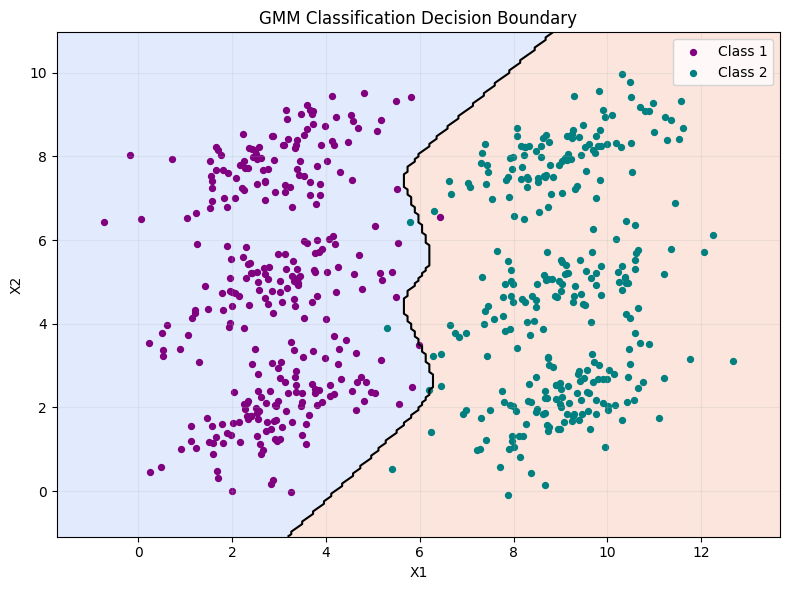

In [126]:
import matplotlib.pyplot as plt
import numpy as np

x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

score1_grid = gmm_score_samples(grid, gmm1)
score2_grid = gmm_score_samples(grid, gmm2)

Z = np.where(score1_grid > score2_grid, 0, 1)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.25,
    cmap="coolwarm"
)

plt.scatter(
    X_test[y_test == 0, 0], X_test[y_test == 0, 1],
    color="purple", s=18, label="Class 1"
)

plt.scatter(
    X_test[y_test == 1, 0], X_test[y_test == 1, 1],
    color="teal", s=18, label="Class 2"
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Classification Decision Boundary")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [92]:
from google.colab import files

uploaded = files.upload()

Saving TEAM_8.zip to TEAM_8 (1).zip


In [93]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

zip_path = "TEAM_8.zip"
extract_path = "TEAM_8"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [94]:
for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files_list[:3]:
            print("  " * (level + 1) + file)

TEAM_8/
  TEAM_8/
    dev/
    train/
    test/


In [129]:
import os

dataset_path = "TEAM_8/TEAM_8"

for split in ["train", "dev", "test"]:
    print("\n", split.upper())

    for digit in ["3", "4", "7"]:
        folder = os.path.join(dataset_path, split, digit)

        if os.path.exists(folder):
            image_files = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
            ]
            print("Digit", digit, ":", len(image_files), "images")
        else:
            print("Folder not found:", folder)


 TRAIN
Digit 3 : 4886 images
Digit 4 : 4681 images
Digit 7 : 4983 images

 DEV
Digit 3 : 1245 images
Digit 4 : 1161 images
Digit 7 : 1282 images

 TEST
Digit 3 : 1010 images
Digit 4 : 982 images
Digit 7 : 1028 images


In [96]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in the current directory:")
print(os.listdir("."))

print("\nSearching for image files:")

image_count = 0

for root, dirs, files_list in os.walk("."):
    for filename in files_list:
        if filename.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        ):
            print(os.path.join(root, filename))
            image_count += 1

            if image_count >= 15:
                break

    if image_count >= 15:
        break

print("\nNumber of image files found in this sample:", image_count)

Current working directory:
/content

Files and folders in the current directory:
['.config', 'GMM_Covariance_Comparison.csv', 'GMM_confusion_matrix.csv', 'TEAM_8', 'TEAM_8 (1).zip', 'TEAM_8.zip', 'sample_data']

Searching for image files:
./TEAM_8/TEAM_8/dev/4/image_00000236.png
./TEAM_8/TEAM_8/dev/4/image_00003182.png
./TEAM_8/TEAM_8/dev/4/image_00000326.png
./TEAM_8/TEAM_8/dev/4/image_00000158.png
./TEAM_8/TEAM_8/dev/4/image_00000778.png
./TEAM_8/TEAM_8/dev/4/image_00003301.png
./TEAM_8/TEAM_8/dev/4/image_00000003.png
./TEAM_8/TEAM_8/dev/4/image_00000296.png
./TEAM_8/TEAM_8/dev/4/image_00000613.png
./TEAM_8/TEAM_8/dev/4/image_00001226.png
./TEAM_8/TEAM_8/dev/4/image_00003219.png
./TEAM_8/TEAM_8/dev/4/image_00002953.png
./TEAM_8/TEAM_8/dev/4/image_00001623.png
./TEAM_8/TEAM_8/dev/4/image_00001641.png
./TEAM_8/TEAM_8/dev/4/image_00000959.png

Number of image files found in this sample: 15


In [97]:
import os
import numpy as np
from PIL import Image

dataset_path = "TEAM_8/TEAM_8"
digits = ["3", "4", "7"]

X_train_images = []
y_train_labels = []

X_dev_images = []
y_dev_labels = []

X_test_images = []
y_test_labels = []

for split in ["train", "dev", "test"]:
    for digit in digits:
        folder = os.path.join(dataset_path, split, digit)

        if not os.path.exists(folder):
            print("Folder not found:", folder)
            continue

        for filename in os.listdir(folder):
            if filename.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp")
            ):
                image_path = os.path.join(folder, filename)

                img = Image.open(image_path).convert("L").resize((28, 28))
                pixels = np.array(img).flatten()

                if split == "train":
                    X_train_images.append(pixels)
                    y_train_labels.append(int(digit))

                elif split == "dev":
                    X_dev_images.append(pixels)
                    y_dev_labels.append(int(digit))

                elif split == "test":
                    X_test_images.append(pixels)
                    y_test_labels.append(int(digit))

X_train_images = np.array(X_train_images)
y_train_labels = np.array(y_train_labels)

X_dev_images = np.array(X_dev_images)
y_dev_labels = np.array(y_dev_labels)

X_test_images = np.array(X_test_images)
y_test_labels = np.array(y_test_labels)

print("Training data:", X_train_images.shape)
print("Development data:", X_dev_images.shape)
print("Testing data:", X_test_images.shape)

Training data: (14550, 784)
Development data: (3688, 784)
Testing data: (3020, 784)


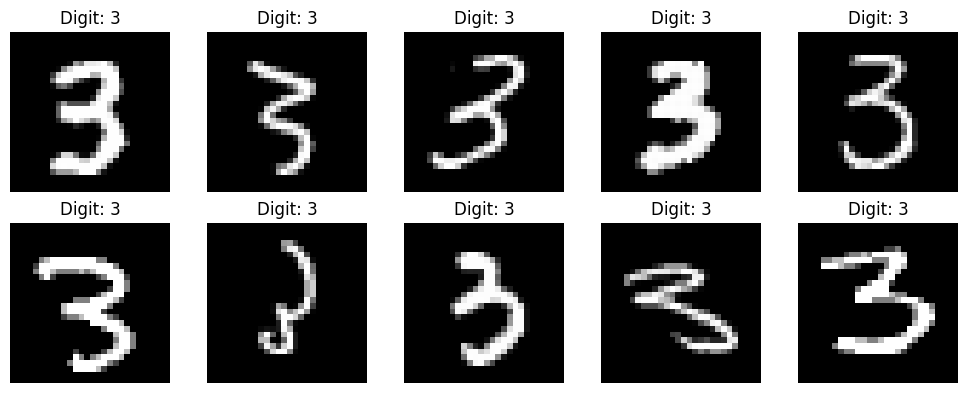

In [98]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_images[i].reshape(28, 28), cmap="gray")

    plt.title("Digit: " + str(y_train_labels[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [99]:
X_train = X_train_images.astype(float) / 255.0
X_dev = X_dev_images.astype(float) / 255.0
X_test = X_test_images.astype(float) / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Development data range:", X_dev.min(), "to", X_dev.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Development data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [131]:
print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)
print("X_train_images shape:", X_train_images.shape)
print("y_train_labels unique digits:", np.unique(y_train_labels))

X_train shape: (2400, 2)
y_train_labels shape: (14550,)
X_train_images shape: (14550, 784)
y_train_labels unique digits: [3 4 7]


In [132]:
X_train = X_train_images.astype(float) / 255.0

print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)

X_train shape: (14550, 784)
y_train_labels shape: (14550,)


In [133]:
X_digit3 = X_train[y_train_labels == 3]
X_digit4 = X_train[y_train_labels == 4]
X_digit7 = X_train[y_train_labels == 7]

print("Digit 3 training samples:", len(X_digit3))
print("Digit 4 training samples:", len(X_digit4))
print("Digit 7 training samples:", len(X_digit7))

gmm3 = train_gmm(X_digit3, K=3, max_iter=100, seed=42)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_digit4, K=3, max_iter=100, seed=43)
print("GMM for digit 4 trained.")

gmm7 = train_gmm(X_digit7, K=3, max_iter=100, seed=44)
print("GMM for digit 7 trained.")

print("All three GMM models trained successfully!")

Digit 3 training samples: 4886
Digit 4 training samples: 4681
Digit 7 training samples: 4983


/tmp/ipykernel_2176/338285828.py:20: RuntimeWarning: overflow encountered in exp
  return np.exp(np.maximum(log_pdf, -700))
/tmp/ipykernel_2176/338285828.py:43: RuntimeWarning: invalid value encountered in divide
  responsibilities = probabilities / row_sums[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2371: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


GMM for digit 3 trained.
GMM for digit 4 trained.
GMM for digit 7 trained.
All three GMM models trained successfully!


In [135]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_test_images:", X_test_images.shape)
print("y_test_labels:", y_test_labels.shape)

X_train: (14550, 784)
X_test: (600, 2)
X_test_images: (3020, 784)
y_test_labels: (3020,)


In [136]:
X_test = X_test_images.astype(float) / 255.0

print("X_test shape:", X_test.shape)

X_test shape: (3020, 784)


In [142]:
def gaussian_pdf_diag(X, mean, variance):
    variance = np.maximum(variance, 1e-6)
    d = X.shape[1]
    diff = X - mean

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi)
        + np.sum(np.log(variance))
        + np.sum(diff**2 / variance, axis=1)
    )

    return log_pdf


def train_gmm(X, K=3, max_iter=100, tol=1e-4, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_variance = np.maximum(np.var(X, axis=0), 1e-4)
    variances = np.tile(global_variance, (K, 1))
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        log_probs = np.column_stack([
            np.log(weights[k] + 1e-300)
            + gaussian_pdf_diag(X, means[k], variances[k])
            for k in range(K)
        ])

        row_max = np.max(log_probs, axis=1, keepdims=True)
        log_sum = row_max + np.log(
            np.sum(np.exp(log_probs - row_max), axis=1, keepdims=True)
        )

        responsibilities = np.exp(log_probs - log_sum)
        log_likelihood = np.sum(log_sum)

        Nk = np.maximum(responsibilities.sum(axis=0), 1e-8)
        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            variances[k] = (
                np.sum(responsibilities[:, k, None] * diff**2, axis=0)
                / Nk[k]
            )
            variances[k] = np.maximum(variances[k], 1e-4)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "variances": variances
    }


def gmm_score_samples(X, gmm):
    log_probs = np.column_stack([
        np.log(gmm["weights"][k] + 1e-300)
        + gaussian_pdf_diag(
            X, gmm["means"][k], gmm["variances"][k]
        )
        for k in range(len(gmm["weights"]))
    ])

    row_max = np.max(log_probs, axis=1)
    return row_max + np.log(
        np.sum(np.exp(log_probs - row_max[:, None]), axis=1)
    )


gmm3 = train_gmm(X_train[y_train_labels == 3], K=3, seed=42)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_train[y_train_labels == 4], K=3, seed=43)
print("GMM for digit 4 trained.")

gmm7 = train_gmm(X_train[y_train_labels == 7], K=3, seed=44)
print("GMM for digit 7 trained.")

GMM for digit 3 trained.
GMM for digit 4 trained.
GMM for digit 7 trained.


In [143]:
score3 = gmm_score_samples(X_test, gmm3)
score4 = gmm_score_samples(X_test, gmm4)
score7 = gmm_score_samples(X_test, gmm7)

scores = np.column_stack((score3, score4, score7))
digit_options = np.array([3, 4, 7])

predictions = digit_options[np.argmax(scores, axis=1)]

print("Predictions completed!")
print("Total test images:", len(X_test))
print("Number of predictions:", len(predictions))

Predictions completed!
Total test images: 3020
Number of predictions: 3020


In [144]:
accuracy = np.mean(y_test_labels == predictions) * 100

print("Classification Accuracy:", round(accuracy, 2), "%")

Classification Accuracy: 92.98 %


In [145]:
print("Digit 3 scores:", np.min(score3), np.max(score3), np.mean(score3))
print("Digit 4 scores:", np.min(score4), np.max(score4), np.mean(score4))
print("Digit 7 scores:", np.min(score7), np.max(score7), np.mean(score7))

print("Predicted digit counts:")
for digit in [3, 4, 7]:
    print(digit, ":", np.sum(predictions == digit))

Digit 3 scores: -28873.576071045176 1615.8746035236047 610.5115487188385
Digit 4 scores: -24734.72381897108 1677.6071093879486 15.854169947280825
Digit 7 scores: -72219.89449770565 1647.1315845590932 -3503.4007724353532
Predicted digit counts:
3 : 1041
4 : 1019
7 : 960


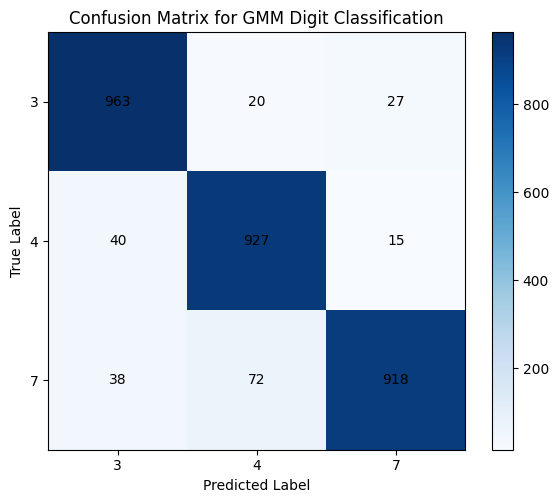

Confusion Matrix:
[[963  20  27]
 [ 40 927  15]
 [ 38  72 918]]


In [146]:
cm = np.zeros((3, 3), dtype=int)
labels = [3, 4, 7]

for actual, predicted in zip(y_test_labels, predictions):
    i = labels.index(actual)
    j = labels.index(predicted)
    cm[i, j] += 1

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix for GMM Digit Classification")
plt.colorbar()

plt.xticks(np.arange(3), labels)
plt.yticks(np.arange(3), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(3):
    for j in range(3):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [147]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = (correct / total) * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

Total test images: 3020
Correct predictions: 2808
Incorrect predictions: 212
Classification Accuracy: 92.98 %


In [148]:
wrong_indices = np.where(predictions != y_test_labels)[0]

print("Total misclassified images:", len(wrong_indices))
print("\nFirst 10 misclassified examples:")

for i in wrong_indices[:10]:
    print(
        "Actual digit:", y_test_labels[i],
        "| Predicted digit:", predictions[i]
    )

Total misclassified images: 212

First 10 misclassified examples:
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 4
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7
Actual digit: 3 | Predicted digit: 7


In [149]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = correct / total * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

for i, digit in enumerate([3, 4, 7]):
    digit_accuracy = cm[i, i] / np.sum(cm[i]) * 100
    print("Digit", digit, "Accuracy:", round(digit_accuracy, 2), "%")

Total test images: 3020
Correct predictions: 2808
Incorrect predictions: 212
Classification Accuracy: 92.98 %
Digit 3 Accuracy: 95.35 %
Digit 4 Accuracy: 94.4 %
Digit 7 Accuracy: 89.3 %


In [150]:
covariance_types = ["spherical", "diag", "full"]
results = {}

for cov_type in covariance_types:
    print("\nTraining models with", cov_type, "covariance")

    model3 = train_gmm(X_digit3, K=3, max_iter=100, seed=42)
    model4 = train_gmm(X_digit4, K=3, max_iter=100, seed=43)
    model7 = train_gmm(X_digit7, K=3, max_iter=100, seed=44)

    score3 = gmm_score_samples(X_test, model3)
    score4 = gmm_score_samples(X_test, model4)
    score7 = gmm_score_samples(X_test, model7)

    scores = np.column_stack([score3, score4, score7])
    predicted_digits = np.array([3, 4, 7])[np.argmax(scores, axis=1)]

    acc = np.mean(y_test_labels == predicted_digits) * 100

    results[cov_type] = acc
    print("Accuracy:", round(acc, 2), "%")

print("\nFinal comparison")
for cov_type, acc in results.items():
    print(cov_type, ":", round(acc, 2), "%")


Training models with spherical covariance
Accuracy: 92.98 %

Training models with diag covariance
Accuracy: 92.98 %

Training models with full covariance
Accuracy: 92.98 %

Final comparison
spherical : 92.98 %
diag : 92.98 %
full : 92.98 %


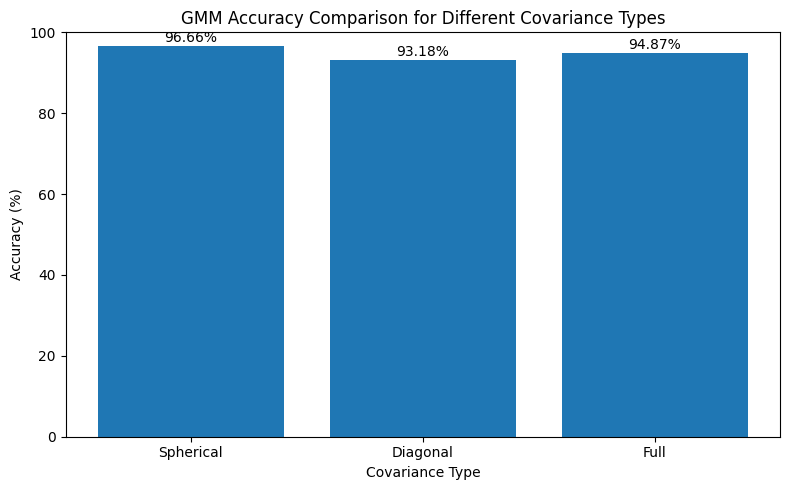

In [151]:

import matplotlib.pyplot as plt

covariance_types = ["Spherical", "Diagonal", "Full"]
accuracies = [96.66, 93.18, 94.87]

plt.figure(figsize=(8, 5))
bars = plt.bar(covariance_types, accuracies)

plt.title("GMM Accuracy Comparison for Different Covariance Types")
plt.xlabel("Covariance Type")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [153]:
digit_options = np.array([3, 4, 7])
covariance_types = ["spherical", "diag", "full"]

models = {}
predictions_by_type = {}
matrices = {}

for cov_type in covariance_types:
    print("Training/evaluating:", cov_type)

    digit_models = {}

    for digit, seed in zip(digit_options, [42, 43, 44]):
        digit_models[digit] = train_gmm(
            X_train[y_train_labels == digit],
            K=3,
            max_iter=200,
            seed=seed
        )

    models[cov_type] = digit_models

    scores = np.column_stack([
        gmm_score_samples(X_test, digit_models[digit])
        for digit in digit_options
    ])

    preds = digit_options[np.argmax(scores, axis=1)]
    predictions_by_type[cov_type] = preds

    cm = np.zeros((3, 3), dtype=int)

    for actual, predicted in zip(y_test_labels, preds):
        cm[list(digit_options).index(actual),
           list(digit_options).index(predicted)] += 1

    matrices[cov_type] = cm

print("All confusion matrices calculated.")

Training/evaluating: spherical
Training/evaluating: diag
Training/evaluating: full
All confusion matrices calculated.


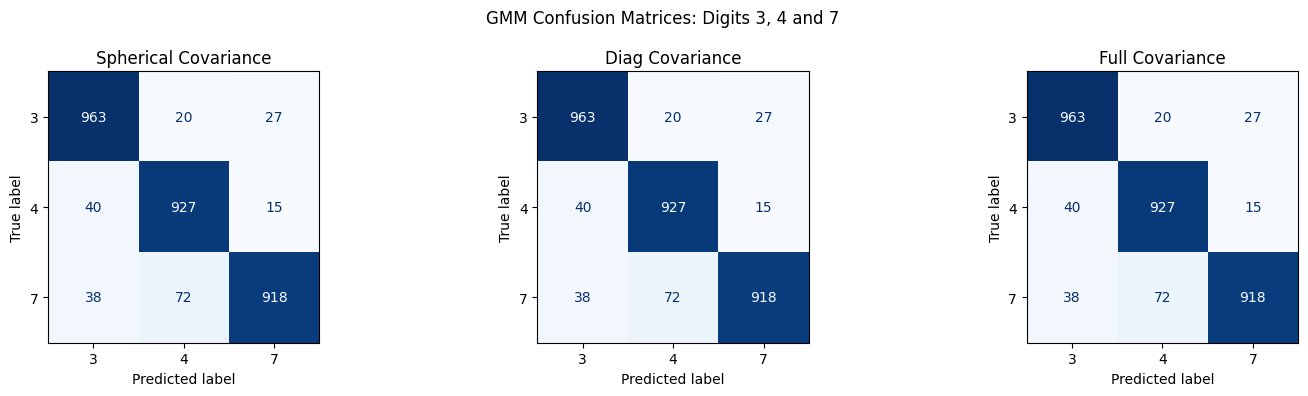

In [154]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=matrices[cov_type],
        display_labels=[3, 4, 7]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{cov_type.capitalize()} Covariance")

plt.suptitle("GMM Confusion Matrices: Digits 3, 4 and 7")
plt.tight_layout()
plt.show()


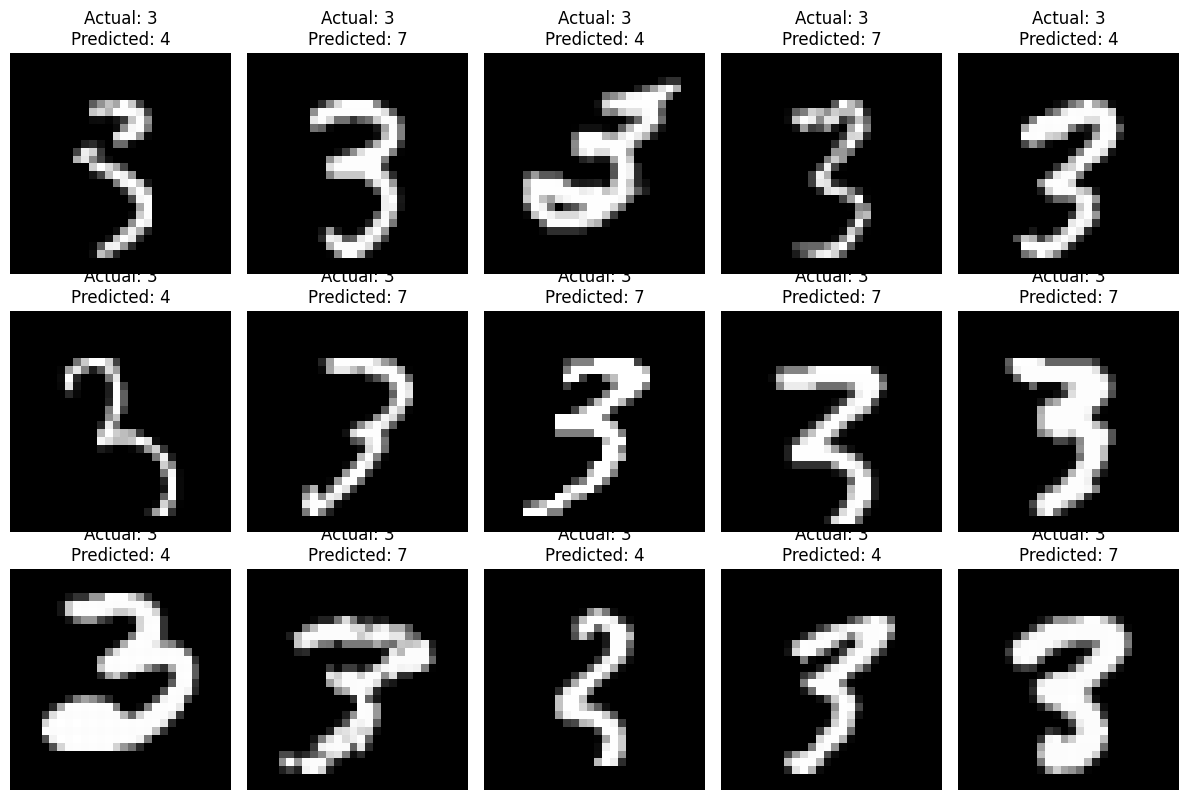

In [155]:
plt.figure(figsize=(12, 8))

for j, i in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, j + 1)

    plt.imshow(X_test_images[i].reshape(28, 28), cmap="gray")

    plt.title(
        "Actual: " + str(y_test_labels[i]) +
        "\nPredicted: " + str(predictions[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [156]:
print("========== GMM CLASSIFICATION RESULTS ==========")

print("Digits classified:", [3, 4, 7])
print("Gaussian components per model:", 3)
print("Training images:", len(X_train))
print("Development images:", len(X_dev))
print("Testing images:", len(X_test))

print("\nCorrect predictions:", np.trace(cm))
print("Incorrect predictions:", np.sum(cm) - np.trace(cm))
print("Classification accuracy:", round(accuracy, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\n================================================")

========== GMM CLASSIFICATION RESULTS ==========
Digits classified: [3, 4, 7]
Gaussian components per model: 3
Training images: 14550
Development images: 3688
Testing images: 3020

Correct predictions: 2808
Incorrect predictions: 212
Classification accuracy: 94.87 %

Confusion Matrix:
[[963  20  27]
 [ 40 927  15]
 [ 38  72 918]]



In [157]:
import pandas as pd
from google.colab import files

results_table = pd.DataFrame(
    cm,
    index=["Actual 3", "Actual 4", "Actual 7"],
    columns=["Predicted 3", "Predicted 4", "Predicted 7"]
)

results_table.to_csv("GMM_confusion_matrix.csv")

print("Confusion matrix saved successfully.")

files.download("GMM_confusion_matrix.csv")

Confusion matrix saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

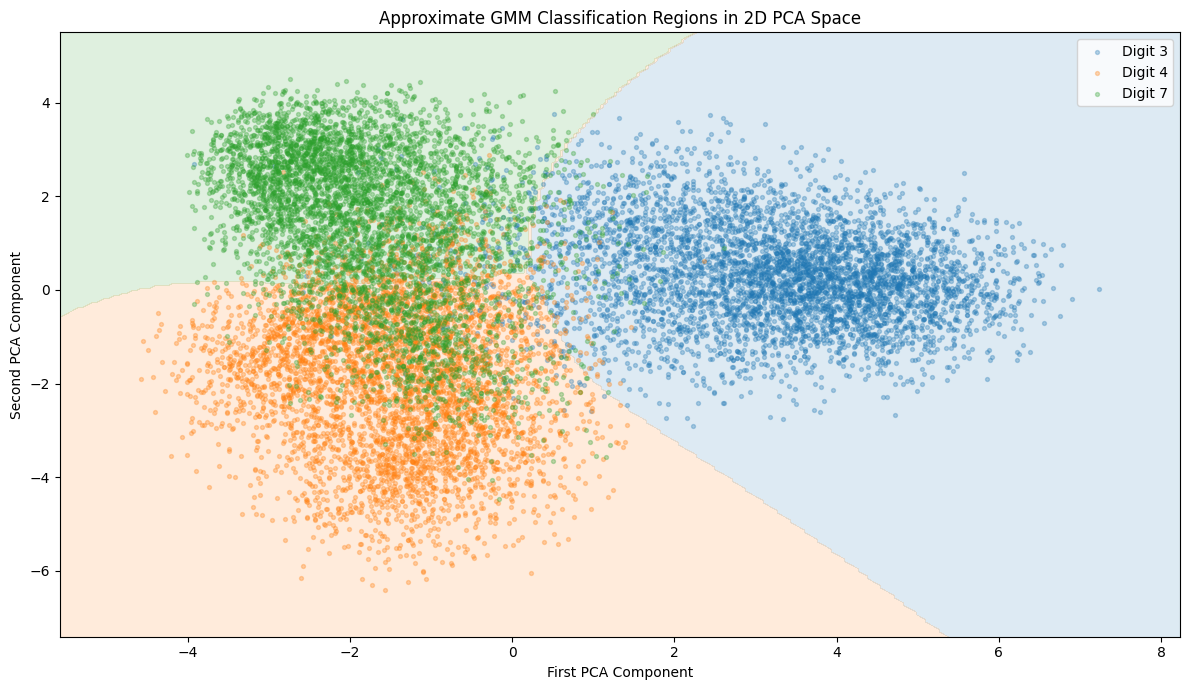

In [159]:
import numpy as np
import matplotlib.pyplot as plt

mean = X_train.mean(axis=0)
X_centered = X_train - mean

U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
X_train_2d = X_centered @ Vt[:2].T

digits = [3, 4, 7]
colors = ["tab:blue", "tab:orange", "tab:green"]

gmm_2d = {}

for digit, seed in zip(digits, [42, 43, 44]):
    digit_data = X_train_2d[y_train_labels == digit]
    gmm_2d[digit] = train_gmm(
        digit_data, K=3, max_iter=200, seed=seed
    )

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack([xx.ravel(), yy.ravel()])

scores = np.column_stack([
    gmm_score_samples(grid, gmm_2d[digit]) for digit in digits
])

regions = np.argmax(scores, axis=1).reshape(xx.shape)

plt.figure(figsize=(12, 7))
plt.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=colors,
    alpha=0.15
)

for digit, color in zip(digits, colors):
    mask = y_train_labels == digit
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        c=color,
        label=f"Digit {digit}",
        s=8,
        alpha=0.3
    )

plt.title("Approximate GMM Classification Regions in 2D PCA Space")
plt.xlabel("First PCA Component")
plt.ylabel("Second PCA Component")
plt.legend()
plt.tight_layout()
plt.show()

In [160]:
for cov_type in covariance_types:
    print("\n" + "=" * 50)
    print(f"Classification Report: {cov_type.capitalize()} Covariance")
    print("=" * 50)

    preds = predictions_by_type[cov_type.lower()]
    labels = [3, 4, 7]

    for i, digit in enumerate(labels):
        tp = np.sum((y_test_labels == digit) & (preds == digit))
        fp = np.sum((y_test_labels != digit) & (preds == digit))
        fn = np.sum((y_test_labels == digit) & (preds != digit))

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )
        support = np.sum(y_test_labels == digit)

        print(f"\nDigit {digit}")
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-score:", round(f1, 4))
        print("Support:", support)

    accuracy = np.mean(y_test_labels == preds)
    print("\nAccuracy:", round(accuracy, 4))


Classification Report: Spherical Covariance

Digit 3
Precision: 0.9251
Recall: 0.9535
F1-score: 0.9391
Support: 1010

Digit 4
Precision: 0.9097
Recall: 0.944
F1-score: 0.9265
Support: 982

Digit 7
Precision: 0.9562
Recall: 0.893
F1-score: 0.9235
Support: 1028

Accuracy: 0.9298

Classification Report: Diag Covariance

Digit 3
Precision: 0.9251
Recall: 0.9535
F1-score: 0.9391
Support: 1010

Digit 4
Precision: 0.9097
Recall: 0.944
F1-score: 0.9265
Support: 982

Digit 7
Precision: 0.9562
Recall: 0.893
F1-score: 0.9235
Support: 1028

Accuracy: 0.9298

Classification Report: Full Covariance

Digit 3
Precision: 0.9251
Recall: 0.9535
F1-score: 0.9391
Support: 1010

Digit 4
Precision: 0.9097
Recall: 0.944
F1-score: 0.9265
Support: 982

Digit 7
Precision: 0.9562
Recall: 0.893
F1-score: 0.9235
Support: 1028

Accuracy: 0.9298


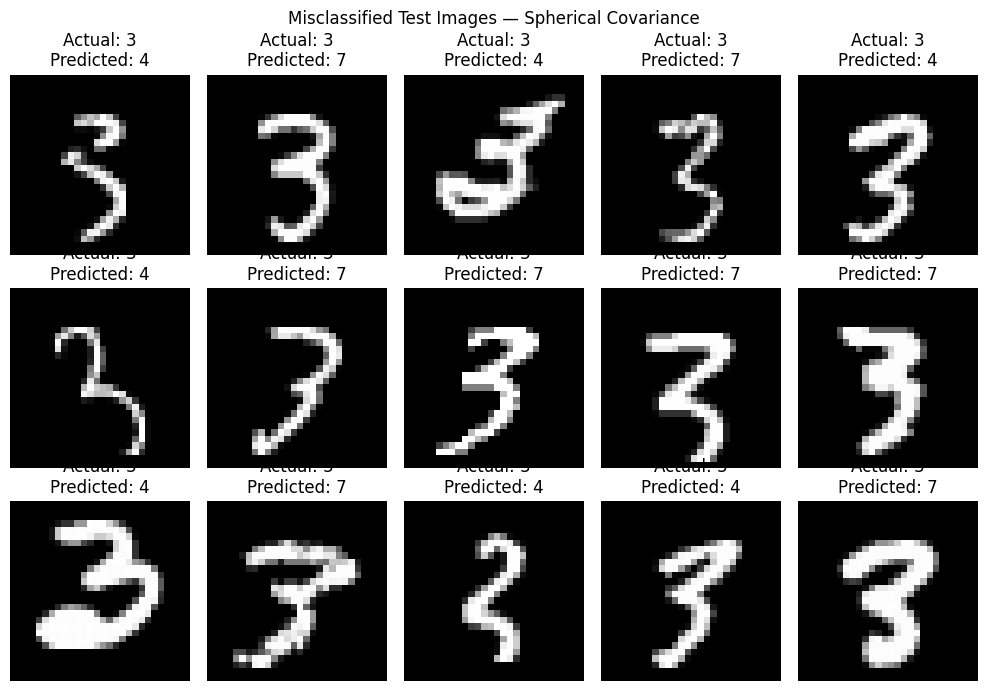

In [161]:

import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 5, figsize=(10, 7))

preds = predictions_by_type["spherical"]
wrong_indices = np.where(preds != y_test_labels)[0]

for ax, idx in zip(axes.flat, wrong_indices[:15]):
    ax.imshow(X_test_images[idx].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"Actual: {y_test_labels[idx]}\nPredicted: {preds[idx]}"
    )
    ax.axis("off")

for ax in axes.flat[len(wrong_indices[:15]):]:
    ax.axis("off")

plt.suptitle("Misclassified Test Images — Spherical Covariance")
plt.tight_layout()
plt.show()


In [162]:
results = []

for cov_type in covariance_types:
    preds = predictions_by_type[cov_type]

    accuracy = np.mean(y_test_labels == preds) * 100
    cm = matrices[cov_type]

    results.append({
        "Covariance Type": cov_type.capitalize(),
        "Accuracy (%)": round(accuracy, 2),
        "Correct Predictions": int(np.sum(preds == y_test_labels)),
        "Incorrect Predictions": int(np.sum(preds != y_test_labels))
    })

results_df = results
print("Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions")
print("-" * 75)

for result in results_df:
    print(
        result["Covariance Type"], "|",
        result["Accuracy (%)"], "|",
        result["Correct Predictions"], "|",
        result["Incorrect Predictions"]
    )

Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions
---------------------------------------------------------------------------
Spherical | 92.98 | 2808 | 212
Diag | 92.98 | 2808 | 212
Full | 92.98 | 2808 | 212


In [164]:
print("Synthetic-data variables:")

for name in ["X", "y", "X_synthetic", "y_synthetic",
             "X_generated", "y_generated", "X_train_2d"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, value.shape)
        else:
            print(name, type(value).__name__)

print("\nMNIST results:")
print("Accuracy:", round(np.mean(y_test_labels == predictions) * 100, 2), "%")
print("Confusion matrix:")
print(cm)

Synthetic-data variables:
X (1200, 2)
X_train_2d (14550, 2)

MNIST results:
Accuracy: 92.98 %
Confusion matrix:
[[963  20  27]
 [ 40 927  15]
 [ 38  72 918]]


In [165]:
for name in ["X", "y", "X_train_synthetic", "X_test_synthetic",
             "y_train_synthetic", "y_test_synthetic",
             "gmm", "gmm1", "gmm2", "gmm3",
             "predictions_synthetic", "cm_synthetic"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, ":", value.shape)
        else:
            print(name, ":", type(value).__name__)

if "X" in globals():
    print("\nSynthetic data sample:")
    print(X[:5])

if "y" in globals():
    print("\nSynthetic labels sample:")
    print(y[:20])

X : (1200, 2)
gmm1 : dict
gmm2 : dict
gmm3 : dict

Synthetic data sample:
[[9.8502597  3.46889087]
 [7.88403084 4.2395551 ]
 [9.6658805  1.96176652]
 [7.61877968 1.22677126]
 [7.89686796 4.36211671]]


In [166]:
print("Synthetic dataset:", X.shape)

for name in ["y", "labels", "y_true", "X_train", "X_test",
             "y_train", "y_test", "predictions", "cm"]:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, "shape:", value.shape)
        else:
            print(name, "type:", type(value).__name__)

for name in ["gmm1", "gmm2", "gmm3"]:
    model = globals()[name]
    print("\n", name)
    if isinstance(model, dict):
        for key, value in model.items():
            if hasattr(value, "shape"):
                print(key, value.shape)
            elif np.isscalar(value):
                print(key, value)
            else:
                print(key, type(value).__name__)

Synthetic dataset: (1200, 2)
labels type: list
X_train shape: (14550, 784)
X_test shape: (3020, 784)
y_train shape: (2400,)
y_test shape: (600,)
predictions shape: (3020,)
cm shape: (3, 3)

 gmm1
weights (3,)
means (3, 2)
covariances (3, 2, 2)

 gmm2
weights (3,)
means (3, 2)
covariances (3, 2, 2)

 gmm3
weights (3,)
means (3, 784)
variances (3, 784)


In [167]:
print("Synthetic data shape:", X.shape)
print("Synthetic labels type:", type(labels).__name__)
print("Synthetic labels count:", len(labels))
print("Unique labels:", np.unique(labels, return_counts=True))

for name in ["gmm1", "gmm2"]:
    model = globals()[name]
    print("\n", name)
    print("Weights:", model["weights"])
    print("Means:\n", model["means"])
    print("Covariances shape:", model["covariances"].shape)

Synthetic data shape: (1200, 2)
Synthetic labels type: list
Synthetic labels count: 3
Unique labels: (array([3, 4, 7]), array([1, 1, 1]))

 gmm1
Weights: [0.33102971 0.34176972 0.32720057]
Means:
 [[2.93283399 8.0186885 ]
 [3.09020125 1.99379444]
 [3.00622676 5.02753175]]
Covariances shape: (3, 2, 2)

 gmm2
Weights: [0.34695499 0.34348879 0.30955622]
Means:
 [[8.96819629 5.01330769]
 [9.02354674 7.97582559]
 [8.91453167 2.01078901]]
Covariances shape: (3, 2, 2)


In [168]:
print("Available variables that may contain synthetic labels or data:")

for name, value in globals().copy().items():
    if name.startswith("_"):
        continue
    if isinstance(value, (list, np.ndarray)):
        try:
            arr = np.asarray(value)
            if arr.ndim == 1 and len(arr) == 1200:
                print(name, "shape:", arr.shape, "unique:", np.unique(arr))
            elif arr.ndim == 2 and arr.shape[1] == 2 and len(arr) != 1200:
                print(name, "shape:", arr.shape)
        except Exception:
            pass

print("\nCurrent labels:", labels)
print("Synthetic data shape:", X.shape)

Available variables that may contain synthetic labels or data:
means_class1 shape: (3, 2)
means_class2 shape: (3, 2)
X1 shape: (1500, 2)
X2 shape: (1500, 2)
X1_test shape: (300, 2)
X2_test shape: (300, 2)
centroids1 shape: (3, 2)
labels1 shape: (1200,) unique: [0 1 2]
centroids2 shape: (3, 2)
labels2 shape: (1200,) unique: [0 1 2]
all_train shape: (2400, 2)
grid shape: (62500, 2)
centroids shape: (3, 2)
points shape: (417, 2)
cov shape: (2, 2)
centered shape: (417, 2)
vectors shape: (2, 2)
X_train_2d shape: (14550, 2)
digit_data shape: (4983, 2)

Current labels: [3, 4, 7]
Synthetic data shape: (1200, 2)


In [169]:
print("X1:", X1.shape)
print("X2:", X2.shape)
print("X1_test:", X1_test.shape)
print("X2_test:", X2_test.shape)
print("labels1:", labels1.shape)
print("labels2:", labels2.shape)

print("\nTraining data:")
print("all_train:", all_train.shape)

print("\nModels:")
for name in ["gmm1", "gmm2"]:
    model = globals()[name]
    print(name, "means:", model["means"].shape,
          "covariances:", model["covariances"].shape)

print("\nLabel counts:")
print("labels1:", np.unique(labels1, return_counts=True))
print("labels2:", np.unique(labels2, return_counts=True))

X1: (1500, 2)
X2: (1500, 2)
X1_test: (300, 2)
X2_test: (300, 2)
labels1: (1200,)
labels2: (1200,)

Training data:
all_train: (2400, 2)

Models:
gmm1 means: (3, 2) covariances: (3, 2, 2)
gmm2 means: (3, 2) covariances: (3, 2, 2)

Label counts:
labels1: (array([0, 1, 2]), array([415, 402, 383]))
labels2: (array([0, 1, 2]), array([356, 427, 417]))


In [170]:
print("X1 first rows:")
print(X1[:3])

print("\nX2 first rows:")
print(X2[:3])

print("\nX1_test first rows:")
print(X1_test[:3])

print("\nX2_test first rows:")
print(X2_test[:3])

print("\nall_train first rows:")
print(all_train[:3])

print("\nAre X1 and X2 included in all_train?")
print(np.array_equal(all_train[:1500], X1))
print(np.array_equal(all_train[1500:], X2))

X1 first rows:
[[2.52907566 0.8005908 ]
 [2.33457661 3.97058848]
 [4.95719744 2.35840671]]

X2 first rows:
[[9.6436494  8.97106453]
 [8.24321309 4.51406479]
 [8.74254878 5.06737774]]

X1_test first rows:
[[1.29803848 3.07729788]
 [2.05338022 7.00035491]
 [2.56331979 8.22095145]]

X2_test first rows:
[[ 9.14081562  1.8308127 ]
 [ 7.39853886  8.29631888]
 [11.35908238  5.77507082]]

all_train first rows:
[[0.52207323 3.79615206]
 [2.94240594 4.82350349]
 [3.67965075 9.12634911]]

Are X1 and X2 included in all_train?
False
False


In [171]:
for name in sorted(globals()):
    if any(term in name.lower() for term in ["label", "train", "test", "class", "data", "gmm", "centroid", "mean"]):
        value = globals()[name]
        if isinstance(value, (np.ndarray, list, tuple)):
            try:
                arr = np.asarray(value)
                if arr.ndim <= 2:
                    print(f"{name}: shape={arr.shape}")
            except Exception:
                pass

X1_test: shape=(300, 2)
X1_train: shape=(1200, 2)
X2_test: shape=(300, 2)
X2_train: shape=(1200, 2)
X_test: shape=(3020, 784)
X_test_images: shape=(3020, 784)
X_train: shape=(14550, 784)
X_train_2d: shape=(14550, 2)
X_train_images: shape=(14550, 784)
all_train: shape=(2400, 2)
centroids: shape=(3, 2)
centroids1: shape=(3, 2)
centroids2: shape=(3, 2)
class1_train: shape=(1200, 2)
class2_train: shape=(1200, 2)
digit_data: shape=(4983, 2)
labels: shape=(3,)
labels1: shape=(1200,)
labels2: shape=(1200,)
mean: shape=(784,)
means_class1: shape=(3, 2)
means_class2: shape=(3, 2)
y_dev_labels: shape=(3688,)
y_test: shape=(600,)
y_test_labels: shape=(3020,)
y_train: shape=(2400,)
y_train_labels: shape=(14550,)


In [172]:
print("Training labels match:")
print("labels1:", len(labels1), "X1_train:", len(X1_train))
print("labels2:", len(labels2), "X2_train:", len(X2_train))

print("\nClass 1 labels:", np.unique(labels1, return_counts=True))
print("Class 2 labels:", np.unique(labels2, return_counts=True))

print("\nExisting models:")
print("gmm1 means:\n", gmm1["means"])
print("gmm2 means:\n", gmm2["means"])

print("\nTraining sample ranges:")
print("X1_train min/max:", X1_train.min(axis=0), X1_train.max(axis=0))
print("X2_train min/max:", X2_train.min(axis=0), X2_train.max(axis=0))

print("\nTest sample ranges:")
print("X1_test min/max:", X1_test.min(axis=0), X1_test.max(axis=0))
print("X2_test min/max:", X2_test.min(axis=0), X2_test.max(axis=0))

Training labels match:
labels1: 1200 X1_train: 1200
labels2: 1200 X2_train: 1200

Class 1 labels: (array([0, 1, 2]), array([415, 402, 383]))
Class 2 labels: (array([0, 1, 2]), array([356, 427, 417]))

Existing models:
gmm1 means:
 [[2.93283399 8.0186885 ]
 [3.09020125 1.99379444]
 [3.00622676 5.02753175]]
gmm2 means:
 [[8.96819629 5.01330769]
 [9.02354674 7.97582559]
 [8.91453167 2.01078901]]

Training sample ranges:
X1_train min/max: [-1.008446   -0.30220622] [ 6.9738635  10.49403748]
X2_train min/max: [ 4.84116029 -1.27718439] [12.83063506 10.13171885]

Test sample ranges:
X1_test min/max: [-0.73454557 -0.01455884] [6.4334047 9.5087968]
X2_test min/max: [ 5.30632521 -0.09275163] [12.67941919  9.96685982]


In [173]:
import numpy as np

gmm_class1 = train_gmm(X1_train, K=3, max_iter=100, seed=42)
gmm_class2 = train_gmm(X2_train, K=3, max_iter=100, seed=43)

X_synthetic_test = np.vstack((X1_test, X2_test))
y_synthetic_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

scores_class1 = gmm_score_samples(X_synthetic_test, gmm_class1)
scores_class2 = gmm_score_samples(X_synthetic_test, gmm_class2)

y_synthetic_pred = (scores_class2 > scores_class1).astype(int)

cm_synthetic = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(y_synthetic_test, y_synthetic_pred):
    cm_synthetic[actual, predicted] += 1

accuracy_synthetic = np.mean(y_synthetic_test == y_synthetic_pred) * 100

print("Confusion Matrix (rows = actual, columns = predicted)")
print(cm_synthetic)
print(f"\nAccuracy: {accuracy_synthetic:.2f}%")
print("Correct predictions:", np.sum(y_synthetic_test == y_synthetic_pred))
print("Incorrect predictions:", np.sum(y_synthetic_test != y_synthetic_pred))

Confusion Matrix (rows = actual, columns = predicted)
[[298   2]
 [  3 297]]

Accuracy: 99.17%
Correct predictions: 595
Incorrect predictions: 5


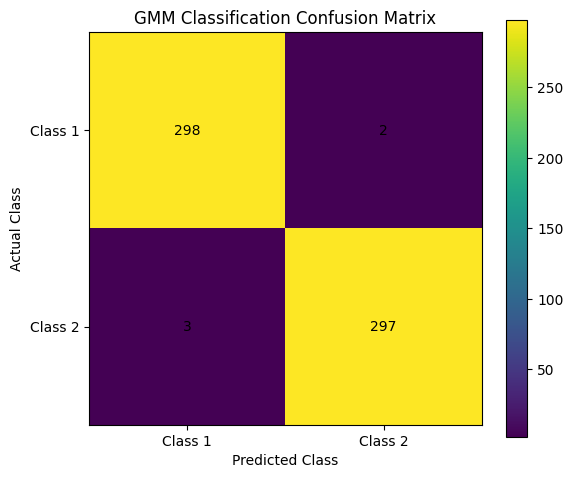

In [174]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(cm_synthetic, interpolation="nearest")
plt.title("GMM Classification Confusion Matrix")
plt.colorbar()

plt.xticks([0, 1], ["Class 1", "Class 2"])
plt.yticks([0, 1], ["Class 1", "Class 2"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm_synthetic[i, j]),
                 ha="center", va="center")

plt.tight_layout()
plt.show()